# Data Analyst Job Market Intelligence
### A Data-Driven Curriculum and Placement Plan Built from 12,000 Indian Job Postings

**Tools:** Python (pandas, matplotlib), MySQL

**Dataset:** `naukri_data_science_jobs_india.csv` (keep the original file untouched, in the same folder as this notebook).


## Business Problem
A training institute wants its Data Analyst program to match what employers actually ask for. Using 12,000 Naukri job postings, this project answers four decisions:

1. **Which skills should be taught first?** (skill demand and skill coverage for fresher jobs)
2. **Which cities should placement efforts target?** (job volume and share of entry-level roles)
3. **Which companies should the institute approach?** (top hirers of fresher Data Analyst roles)
4. **Should the Data Analyst track differ from the Business Analyst and Data Scientist tracks?** (role skill profiles)

## STEP 1: Import Libraries and Load the Data

In [1]:
# Import the libraries
import pandas as pd
import matplotlib.pyplot as plt

# Load the original dataset (keep this file untouched)
df = pd.read_csv("naukri_data_science_jobs_india.csv")

# Check the size, column names, and first rows
print(df.shape)
print(df.columns.tolist())
df.head()

(12000, 5)
['Job_Role', 'Company', 'Location', 'Job Experience', 'Skills/Description']


,Job_Role,Company,Location,Job Experience,Skills/Description
0,Senior Data Scientist,UPL,"Bangalore/Bengaluru, Mumbai (All Areas)",3-6,"python, MLT, statistical modeling, machine lea..."
1,Senior Data Scientist,Walmart,Bangalore/Bengaluru,5-9,"Data Science, Machine learning, Python, Azure,..."
2,Applied Data Scientist / ML Senior Engineer (P...,SAP India Pvt.Ltd,Bangalore/Bengaluru,5-10,"Python, IT Skills, Testing, Cloud, Product Man..."
3,Data Scientist,UPL,"Bangalore/Bengaluru, Mumbai (All Areas)",1-4,"python, machine learning, Data Science, data a..."
4,Data Scientist,Walmart,Bangalore/Bengaluru,4-8,"IT Skills, Python, Data Science, Machine Learn..."


## STEP 2: Check Data Quality (Missing Values and Duplicates)

In [2]:
# Count missing values in each column
print(df.isnull().sum())

# Count duplicate rows
print("Duplicates:", df.duplicated().sum())

# Check the most common job roles
print(df["Job_Role"].value_counts().head(15))

Job_Role              0
Company               0
Location              0
Job Experience        0
Skills/Description    0
dtype: int64
Duplicates: 0
Job_Role
Data Engineer                            580
Data Scientist                           505
Data Analyst                             353
Senior Technical Lead (Data Engineer)    276
Senior Data Engineer                     197
Business Analyst                         197
Senior Data Scientist                     97
Azure Data Engineer                       80
Data Engineer: Data Integration           75
Big Data Engineer                         71
Senior Data Analyst                       66
Big Data Developer                        65
Lead Data Engineer                        55
Data Engineer: Big Data                   55
Senior Software Engineer                  51
Name: count, dtype: int64


## STEP 3: Clean the City Column

In [3]:
# Keep only the first city when a job lists several cities
df["city"] = df["Location"].str.split(",").str[0]

# Remove area names in brackets, for example Pune(Baner) becomes Pune
df["city"] = df["city"].str.replace(r"\(.*\)", "", regex=True).str.strip()

# Merge different spellings of the same city into one name
df["city"] = df["city"].replace({
    "Bangalore/Bengaluru": "Bangalore",
    "Bengaluru": "Bangalore",
    "Bangalore Rural": "Bangalore",
    "Hyderabad/Secunderabad": "Hyderabad",
    "Serilingampally": "Hyderabad",
    "Gurgaon/Gurugram": "Gurugram",
    "Gurgaon": "Gurugram",
    "Gurgaon Gurugram": "Gurugram",
    "Delhi / NCR": "Delhi",
    "Delhi NCR": "Delhi",
    "New Delhi": "Delhi",
    "Navi Mumbai": "Mumbai",
    "Mumbai Suburban": "Mumbai",
    "Thane": "Mumbai",
    "Kochi/Cochin": "Kochi",
    "Trivandrum/Thiruvananthapuram": "Trivandrum",
    "Mysore/Mysuru": "Mysore",
    "Mangaluru/Mangalore": "Mangalore",
    "Panaji/Panjim": "Goa",
    "Panjim": "Goa",
    "South Goa": "Goa",
    "Mohali/SAS Nagar": "Mohali",
    "Greater Noida": "Noida",
    "Calicut/Kozhikode": "Kozhikode",
    "Pondicherry/Puducherry": "Puducherry",
    "Nasik/Nashik": "Nashik",
    "Bhilai/Bhillai": "Bhilai",
    "Bellary/Ballari": "Ballari",
    "Alleppey/Alappuzha": "Alappuzha",
    "Kollam/Quilon": "Kollam",
    "Trichy": "Tiruchirappalli",
    "Maldah/Malda": "Malda",
})

# Make capitalization consistent, for example punjab becomes Punjab
df["city"] = df["city"].str.title()

# Check the cleaned city counts
print(df["city"].value_counts().head(15))

city
Bangalore     3877
Hyderabad     1645
Pune          1465
Mumbai        1163
Gurugram      1010
Chennai        770
Noida          542
Delhi          347
Kolkata        246
Remote         153
Ahmedabad      115
Kochi          115
Mohali          58
Jaipur          49
Chandigarh      44
Name: count, dtype: int64


## STEP 4: Clean the Experience Column and Create Experience Bands

In [4]:
# Extract the minimum experience from text like "5-10"
df["min_exp"] = df["Job Experience"].str.extract(r"(\d+)")[0].astype(float)

# Drop the row where experience is missing
df = df.dropna(subset=["min_exp"])

# Group minimum experience into three bands
def band(x):
    if x <= 2:
        return "0-2 yrs"
    elif x <= 5:
        return "3-5 yrs"
    else:
        return "5+ yrs"

df["exp_band"] = df["min_exp"].apply(band)

# Check how many jobs fall in each band
print(df["exp_band"].value_counts())

exp_band
3-5 yrs    5925
0-2 yrs    3698
5+ yrs     2376
Name: count, dtype: int64


## STEP 5: Extract Skills from the Job Descriptions

In [5]:
# List of skills to search for
skills = ["sql", "excel", "python", "power bi", "tableau", "statistics",
          "machine learning", "aws", "azure", "spark", "hadoop",
          "java", "etl", "snowflake", "sas"]

# Convert the skills text to lowercase so SQL, Sql, and sql match
df["skills_text"] = df["Skills/Description"].str.lower()

# Create one True/False column per skill (whole-word match only)
for s in skills:
    df[s] = df["skills_text"].str.contains(r"\b" + s + r"\b", regex=True, na=False)

# Percentage of all jobs that mention each skill
print((df[skills].mean() * 100).round(1).sort_values(ascending=False))

python              26.7
sql                 18.5
machine learning    15.0
java                10.9
aws                  9.5
spark                9.0
azure                8.5
tableau              6.2
hadoop               6.0
excel                5.9
etl                  5.0
power bi             4.6
sas                  3.2
statistics           1.4
snowflake            1.2
dtype: float64


## STEP 6: Filter Data Analyst Jobs

In [6]:
# Keep only Data Analyst jobs
da = df[df["Job_Role"].str.contains("Data Analyst", case=False)]
print("Data Analyst jobs:", len(da))

# Percentage of Data Analyst jobs that mention each skill
print((da[skills].mean() * 100).round(1).sort_values(ascending=False))

Data Analyst jobs: 1049
sql                 27.1
excel               21.4
python              19.2
tableau             15.8
power bi            11.9
machine learning     6.6
sas                  6.4
etl                  3.9
azure                3.0
hadoop               2.9
spark                2.5
aws                  2.4
statistics           2.0
java                 1.9
snowflake            0.5
dtype: float64


## STEP 7: Save the Clean Data for MySQL

In [7]:
# Select the columns needed in MySQL
jobs = df[["Job_Role", "Company", "city", "Job Experience", "min_exp", "exp_band"] + skills].copy()

# Replace spaces in column names with underscores
jobs.columns = [c.replace(" ", "_") for c in jobs.columns]

# Convert skill columns from True/False to 1/0
skill_cols = [s.replace(" ", "_") for s in skills]
jobs[skill_cols] = jobs[skill_cols].astype(int)

# Save as a new file (does not overwrite the original dataset)
jobs.to_csv("jobs_clean.csv", index=False)
print(jobs.shape)

(11999, 21)


## CHART 1: Most In-Demand Skills in Data Analyst Jobs

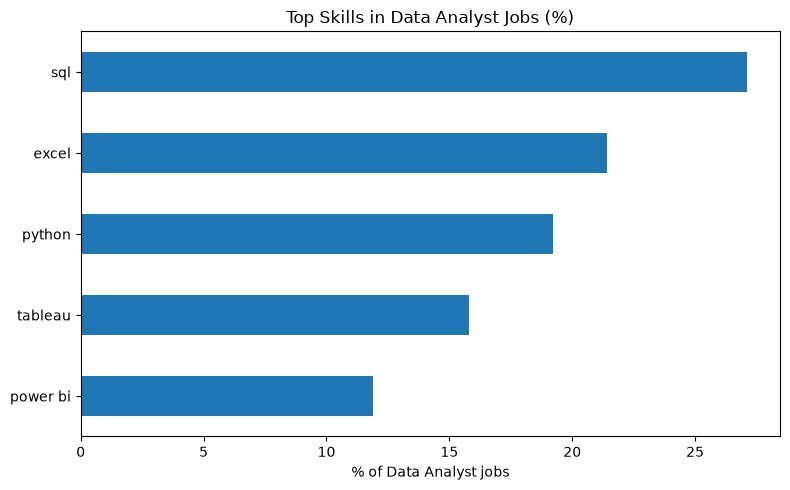

In [8]:
# Percentage of Data Analyst jobs mentioning each skill
skill_pct = (da[["sql", "excel", "python", "power bi", "tableau"]].mean() * 100).round(1).sort_values()

# Horizontal bar chart
skill_pct.plot(kind="barh", title="Top Skills in Data Analyst Jobs (%)", figsize=(8, 5))
plt.xlabel("% of Data Analyst jobs")
plt.tight_layout()
plt.savefig("chart1_skills.png", dpi=150)
plt.show()

## CHART 2: Top 10 Cities for Data Analyst Jobs

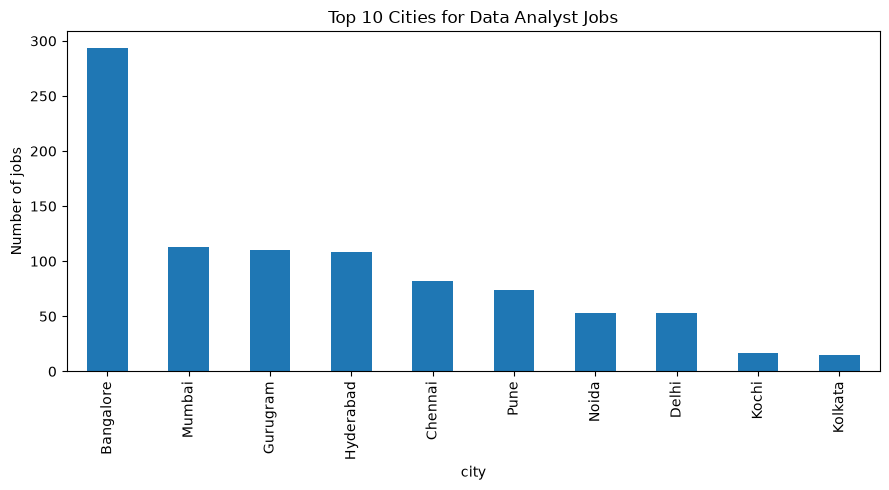

In [9]:
# Exclude "Remote" because it is a job type, not a city
da_city = da[da["city"] != "Remote"]

# Bar chart of the top 10 cities
da_city["city"].value_counts().head(10).plot(kind="bar", title="Top 10 Cities for Data Analyst Jobs", figsize=(9, 5))
plt.ylabel("Number of jobs")
plt.tight_layout()
plt.savefig("chart2_cities.png", dpi=150)
plt.show()

## CHART 3: Data Analyst Jobs by Experience Level

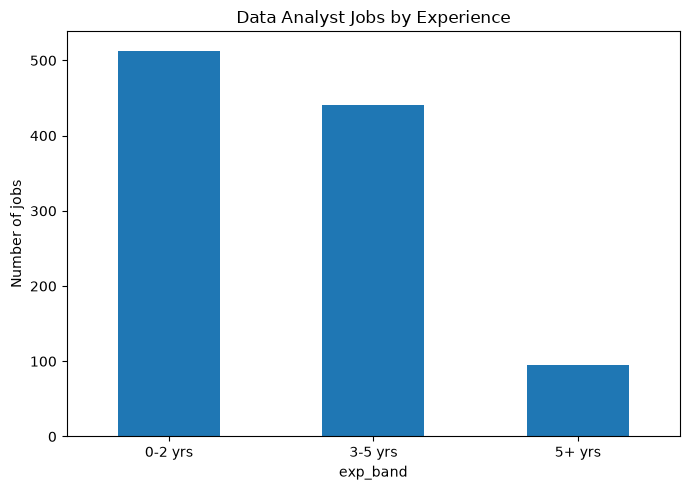

In [10]:
# Number of Data Analyst jobs in each experience band
da["exp_band"].value_counts().reindex(["0-2 yrs", "3-5 yrs", "5+ yrs"]).plot(
    kind="bar", title="Data Analyst Jobs by Experience", figsize=(7, 5))
plt.ylabel("Number of jobs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart3_experience.png", dpi=150)
plt.show()

## CHART 4: Skill Demand by Experience Level (Key Insight)

           sql  excel  python  power bi
exp_band                               
0-2 yrs   22.2   29.4    16.4      10.1
3-5 yrs   31.3   15.6    22.0      12.7
5+ yrs    33.7    5.3    21.1      17.9


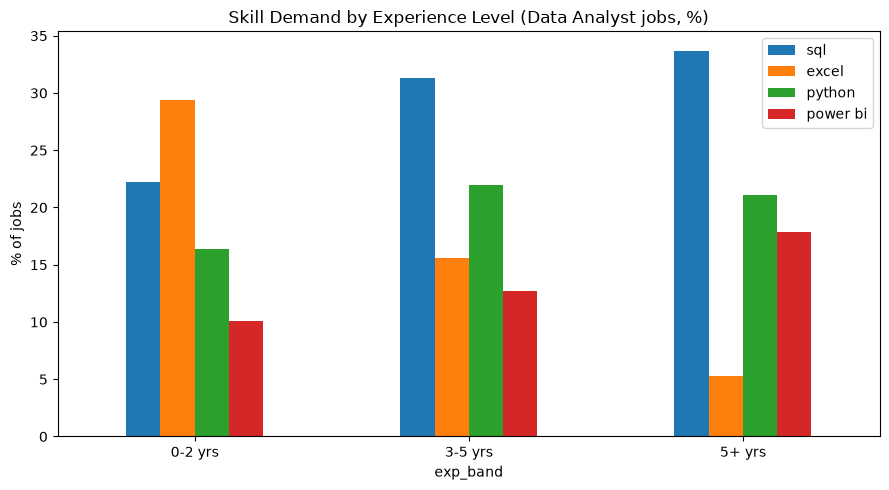

In [11]:
# Percentage of jobs mentioning each skill, by experience band
by_exp = da.groupby("exp_band")[["sql", "excel", "python", "power bi"]].mean() * 100
by_exp = by_exp.reindex(["0-2 yrs", "3-5 yrs", "5+ yrs"]).round(1)
print(by_exp)

# Grouped bar chart
by_exp.plot(kind="bar", title="Skill Demand by Experience Level (Data Analyst jobs, %)", figsize=(9, 5))
plt.ylabel("% of jobs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart4_skills_by_experience.png", dpi=150)
plt.show()

## CHART 5: Skills That Appear Together

          sql  excel  python  power bi  tableau
sql       284     72     102        36       70
excel      72    225      40        26       42
python    102     40     201        41       58
power bi   36     26      41       125       63
tableau    70     42      58        63      166


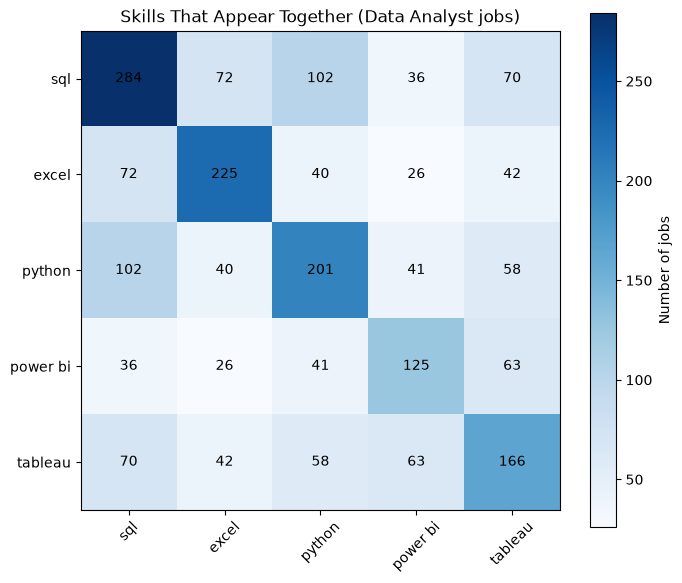

In [12]:
# Count how many Data Analyst jobs mention each pair of skills
pair_skills = ["sql", "excel", "python", "power bi", "tableau"]
pairs = pd.DataFrame(
    [[(da[a] & da[b]).sum() for b in pair_skills] for a in pair_skills],
    index=pair_skills, columns=pair_skills
)
print(pairs)

# Heatmap of skill pairs
plt.figure(figsize=(7, 6))
plt.imshow(pairs, cmap="Blues")
plt.colorbar(label="Number of jobs")
plt.xticks(range(len(pair_skills)), pair_skills, rotation=45)
plt.yticks(range(len(pair_skills)), pair_skills)
for i in range(len(pair_skills)):
    for j in range(len(pair_skills)):
        plt.text(j, i, pairs.iloc[i, j], ha="center", va="center")
plt.title("Skills That Appear Together (Data Analyst jobs)")
plt.tight_layout()
plt.savefig("chart5_skill_pairs.png", dpi=150)
plt.show()

## BUSINESS ANALYSIS A: Skill Coverage for Fresher Jobs
**Decision:** which skills should the curriculum teach, and in what order?

Question: *if a student learns this set of skills, what share of fresher Data Analyst jobs (0-2 years) match?*

Fresher Data Analyst jobs: 513
{'SQL + Excel': 44.2, '+ Tableau / Power BI': 52.6, '+ Python': 55.8}
Fresher jobs listing none of the five skills: 44.2 %


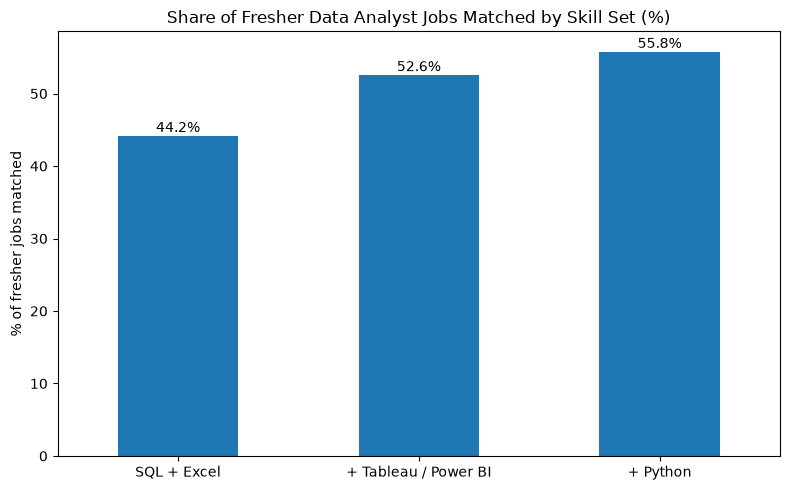

In [13]:
# Fresher Data Analyst jobs (minimum experience 0-2 years)
fresher = da[da["exp_band"] == "0-2 yrs"]
print("Fresher Data Analyst jobs:", len(fresher))

# Skill sets to compare, each one adding to the previous
coverage_sets = {
    "SQL + Excel": ["sql", "excel"],
    "+ Tableau / Power BI": ["sql", "excel", "tableau", "power bi"],
    "+ Python": ["sql", "excel", "tableau", "power bi", "python"],
}

# Share of fresher jobs that mention at least one skill from the set
coverage = {name: round(float(fresher[cols].any(axis=1).mean() * 100), 1)
            for name, cols in coverage_sets.items()}
print(coverage)

# Share of fresher jobs that list none of the five main skills
none_listed = round((~fresher[["sql", "excel", "python", "power bi", "tableau"]].any(axis=1)).mean() * 100, 1)
print("Fresher jobs listing none of the five skills:", none_listed, "%")

# Bar chart
pd.Series(coverage).plot(kind="bar", title="Share of Fresher Data Analyst Jobs Matched by Skill Set (%)", figsize=(8, 5))
plt.ylabel("% of fresher jobs matched")
plt.xticks(rotation=0)
for i, v in enumerate(coverage.values()):
    plt.text(i, v + 0.5, str(v) + "%", ha="center")
plt.tight_layout()
plt.savefig("chart6_skill_coverage.png", dpi=150)
plt.show()

## BUSINESS ANALYSIS B: City Placement Priority
**Decision:** which cities should placement efforts target?

Volume alone is not enough. A city with many jobs but few entry-level roles is a weaker target for freshers, so we also measure the **share of fresher jobs** in each city.

           da_jobs  fresher_pct
city                           
Bangalore      294         49.7
Mumbai         113         54.9
Gurugram       110         41.8
Hyderabad      108         36.1
Chennai         82         46.3
Pune            74         36.5
Delhi           53         58.5
Noida           53         49.1


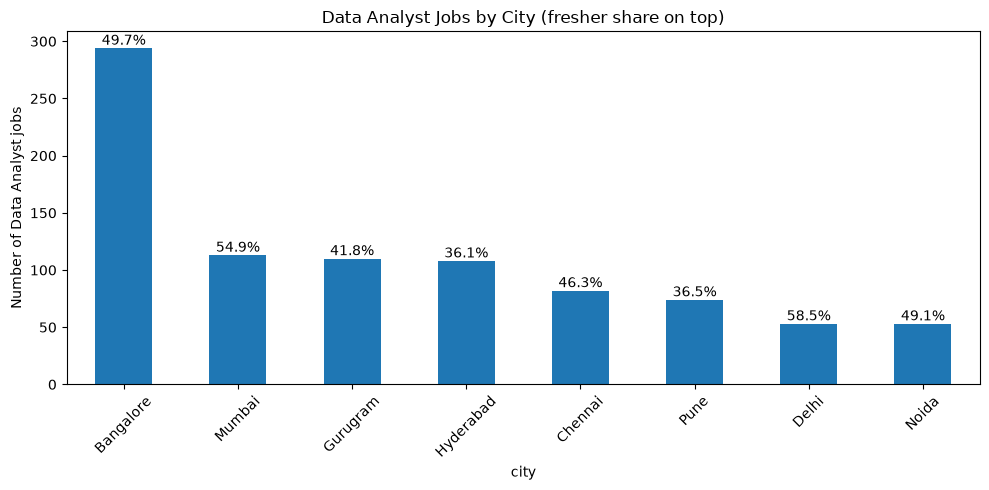

In [14]:
# Jobs and fresher share per city (cities with at least 30 Data Analyst jobs)
city_priority = da_city.groupby("city").agg(
    da_jobs=("min_exp", "size"),
    fresher_pct=("exp_band", lambda x: round((x == "0-2 yrs").mean() * 100, 1))
)
city_priority = city_priority[city_priority["da_jobs"] >= 30].sort_values("da_jobs", ascending=False)
print(city_priority)

# Bar chart of jobs, with the fresher share written above each bar
city_priority["da_jobs"].plot(kind="bar", title="Data Analyst Jobs by City (fresher share on top)", figsize=(10, 5))
for i, (n, pct) in enumerate(zip(city_priority["da_jobs"], city_priority["fresher_pct"])):
    plt.text(i, n + 3, str(pct) + "%", ha="center")
plt.ylabel("Number of Data Analyst jobs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("chart7_city_priority.png", dpi=150)
plt.show()

## BUSINESS ANALYSIS C: Companies to Approach
**Decision:** which employers should the institute build placement relationships with?

Company
Myntra                                14
Deutsche Bank                          7
TalentStack                            7
Right Step Consulting                  7
Diverse Lynx                           7
Seven Consultancy (HR Solution)        6
Huquo Consulting Pvt. Ltd              5
Institutional Shareholder Services     4
Moody's                                4
Reval India Pvt. Ltd.                  4
Name: count, dtype: int64
Companies posting Data Analyst jobs: 699
Companies posting fresher Data Analyst jobs: 394
Share of fresher jobs held by the top 10 companies: 12.7 %


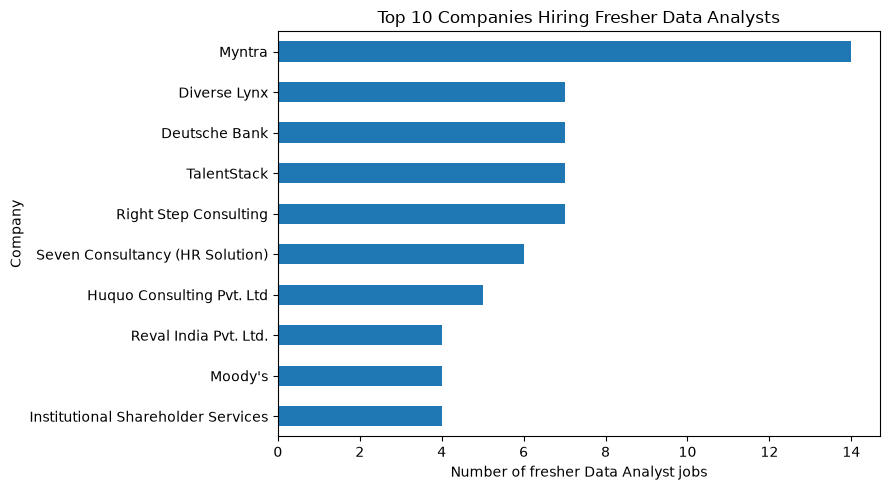

In [15]:
# Companies that post the most fresher Data Analyst jobs
top_comp = fresher["Company"].value_counts().head(10)
print(top_comp)

# How fragmented is the market?
print("Companies posting Data Analyst jobs:", da["Company"].nunique())
print("Companies posting fresher Data Analyst jobs:", fresher["Company"].nunique())
print("Share of fresher jobs held by the top 10 companies:", round(top_comp.sum() / len(fresher) * 100, 1), "%")

# Horizontal bar chart (largest at the top)
top_comp.sort_values().plot(kind="barh", title="Top 10 Companies Hiring Fresher Data Analysts", figsize=(9, 5))
plt.xlabel("Number of fresher Data Analyst jobs")
plt.tight_layout()
plt.savefig("chart8_top_companies.png", dpi=150)
plt.show()

## BUSINESS ANALYSIS D: Role-Based Learning Tracks
**Decision:** should Data Analyst, Business Analyst, and Data Scientist students follow the same curriculum?

role_group
Data Scientist      1378
Data Analyst        1049
Business Analyst     658
Name: count, dtype: int64
                   sql  excel  python  power bi  tableau
role_group                                              
Business Analyst  19.0   11.2     9.6       7.6      9.7
Data Analyst      27.1   21.4    19.2      11.9     15.8
Data Scientist    16.5    0.9    44.4       3.0      6.7


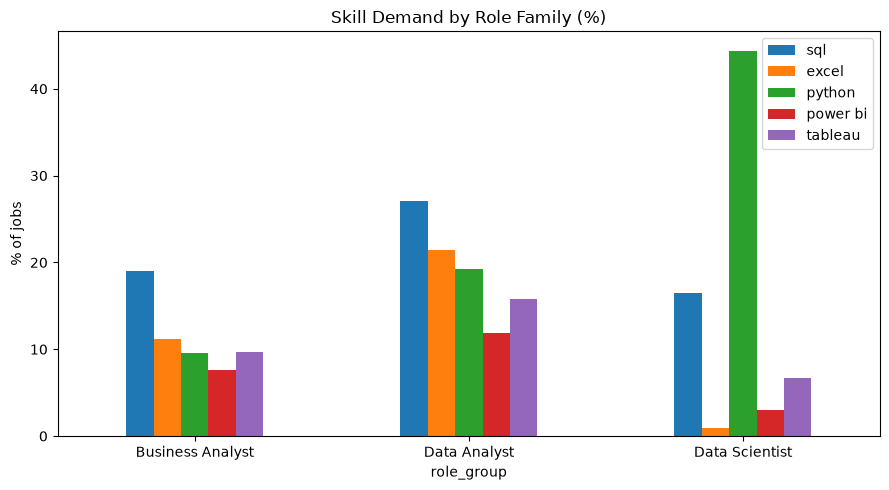

In [16]:
# Group all jobs into three role families
def role_group(role):
    role = role.lower()
    if "data analyst" in role:
        return "Data Analyst"
    elif "business analyst" in role:
        return "Business Analyst"
    elif "data scientist" in role:
        return "Data Scientist"
    return "Other"

df["role_group"] = df["Job_Role"].apply(role_group)
roles = df[df["role_group"] != "Other"]

# Skill demand (%) for each role family
role_skills = (roles.groupby("role_group")[["sql", "excel", "python", "power bi", "tableau"]].mean() * 100).round(1)
print(roles["role_group"].value_counts())
print(role_skills)

# Grouped bar chart
role_skills.plot(kind="bar", title="Skill Demand by Role Family (%)", figsize=(9, 5))
plt.ylabel("% of jobs")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart9_role_tracks.png", dpi=150)
plt.show()

## BUSINESS ANALYSIS E (Optional): Salary
Salary needs a second dataset (AmbitionBox) that cannot be joined row by row with the Naukri data, so analyze it **separately**.

To use it, put `ambitionbox_salary.csv` in this folder and run the next cell. It only prints the columns and first rows, so you can see the real column names before writing the analysis.

In [18]:
import os

# Run only if the salary file is present
if os.path.exists("Data_Science_Jobs_in_India.csv"):
    salary = pd.read_csv("Data_Science_Jobs_in_India.csv")
    print(salary.shape)
    print(salary.columns.tolist())
    display(salary.head())
else:
    print("ambitionbox_salary.csv not found. Skip this section for now.")

(1602, 8)
['Unnamed: 0', 'company_name', 'job_title', 'min_experience', 'avg_salary', 'min_salary', 'max_salary', 'num_of_salaries']


,Unnamed: 0,company_name,job_title,min_experience,avg_salary,min_salary,max_salary,num_of_salaries
0,0,TCS,Data Scientist,2,7.8L,4.5L,16.0L,841
1,1,Accenture,Data Scientist,2,12.8L,5.8L,23.0L,501
2,2,IBM,Data Scientist,2,13.4L,5.3L,25.0L,394
3,3,Cognizant,Data Scientist,2,9.8L,5.0L,18.0L,318
4,4,Capgemini,Data Scientist,2,8.6L,4.8L,14.6L,300


## Recommendations
**1. Teach SQL and Excel first.**
SQL and Excel are the top skills in Data Analyst jobs (27.1% and 21.4%). A student with just these two matches about 44% of fresher Data Analyst jobs.

**2. Add one BI tool second.**
Adding Tableau or Power BI raises the match to about 53%, a gain of roughly 8 points.

**3. Introduce Python third.**
Python adds only about 3 more points for fresher roles (about 56% in total), but its importance grows with experience, so it belongs after the fundamentals.

**4. Teach Excel more heavily for entry-level roles.**
Excel appears in 29.4% of 0-2 year jobs but only 5.3% of 5+ year jobs, while SQL rises from 22.2% to 33.7%.

**5. Target Bangalore first, then Mumbai, Gurugram, and Hyderabad.**
Bangalore has 294 Data Analyst jobs, more than double any other city. Among the five biggest cities, Mumbai has the highest fresher share (about 55%), and Delhi is higher still (about 59%) with fewer jobs. Hyderabad and Pune have the lowest fresher share (about 36%).

**6. Build relationships with repeat hirers, but expect a fragmented market.**
Myntra posts the most fresher roles (14). The top 10 companies hold only about 13% of fresher jobs, and 394 different companies posted fresher roles, so placement outreach must be broad.

**7. Use separate tracks for each role.**
Data Scientist jobs lean on Python (44.4%), Data Analyst jobs on SQL and Excel, and Business Analyst jobs ask for each of these skills less often than Data Analyst jobs do.

## Limitations
- The data was collected in May 2022, so today's market may differ.
- Each posting lists only a few key skills. About 44% of fresher Data Analyst postings list none of the five main skills, so the coverage figures are a **lower bound**. Use the percentages to compare skills, not as exact market shares.
- The dataset came from a "data scientist" search, so Data Analyst jobs are a smaller sample (1,049).
- Experience uses the minimum of each range (for example, "2-5" counts as 2), so the 0-2 band includes roles that require 2 years.
- Skill matching uses a fixed keyword list and misses spelling variants or skills outside the list.
- Salary is not analyzed unless the AmbitionBox file is added.